# بررسی کاربران و زمان در train و test اصلی آمازون

این فایل را در **Colab با CPU** اجرا کنید؛ GPU و آموزش مدل لازم نیست. هر دو فایل اصلی به‌طور کامل بررسی می‌شوند و نصف‌کردن داده انجام نمی‌شود.

هدف: شمارش کاربران هر فایل و اشتراک آن‌ها، توزیع تعداد review هر کاربر، بازه و توزیع زمانی، و مهم‌تر از همه **امکان استفاده از سابقهٔ امتیازدار train برای هر نظر test در زمان ثبت همان نظر**.

تعداد کاربران مشترک با امکان استفاده از سابقه یکی نیست: کاربر ممکن است در train باشد، اما تمام نظرات train او هم‌زمان یا بعد از نظر test باشند.

خواندن فایل‌ها chunk-based است؛ متن کامل در حافظه نگه داشته نمی‌شود، بلکه وجود یا خالی‌بودن آن ثبت می‌شود. خروجی اشتراک‌پذیر شامل متن نظرها و شناسهٔ کاربران نیست. از امتیاز test استفاده نمی‌شود و نیازی به ستون overall در test وجود ندارد.


In [1]:
%pip install -q gdown "pandas>=2.2,<4" matplotlib


## ۱. تنظیمات و دریافت فایل‌ها

`TIME_GRANULARITY="day"` یعنی فقط روزهای قبل مجازند؛ همهٔ نظرات یک روز کنار گذاشته می‌شوند. برای مقایسهٔ زمان دقیق می‌توانید آن را به `"timestamp"` تغییر دهید؛ زمان‌های کاملاً برابر همچنان سابقه محسوب نمی‌شوند. اگر timestampها فقط ساعت صفر داشته باشند، اطلاعات درون‌روزی نداریم.

دانلودهای کامل قبلی دوباره دریافت نمی‌شوند. اگر دریافت Google Drive به علت سهمیه یا مجوز فایل خطا داد، همان CSVها را در مسیرهای `TRAIN_PATH` و `TEST_PATH` قرار دهید و سلول را دوباره اجرا کنید.


In [2]:
from pathlib import Path
from datetime import datetime, timezone
import gdown

DATA_DIR=Path('/content/amazon_original_data')
DATA_DIR.mkdir(parents=True,exist_ok=True)
TRAIN_PATH=DATA_DIR/'train_data.csv'
TEST_PATH=DATA_DIR/'test_data.csv'
TRAIN_FILE_ID='1-AlW7oNJHaqi3xk_9dWHUS52Dzl_FmFW'
TEST_FILE_ID='1-8TsrqTRFP-q9TM-6HinhO0ZVXFHq9TB'
TIME_GRANULARITY='day'  # Alternative: 'timestamp'
CHUNK_SIZE=50000
EXPORT_PER_ROW=False  # Optional larger audit: source row numbers, dates and counts; no user IDs.
OUTPUT_DIR=Path('/content/amazon_dataset_audit')/datetime.now(timezone.utc).strftime('%Y%m%d_%H%M%S_%f')
OUTPUT_DIR.mkdir(parents=True,exist_ok=True)

def download_csv(file_id,path):
    if not path.exists() or path.stat().st_size==0:
        partial=path.with_suffix('.csv.part')
        result=gdown.download(id=file_id,output=str(partial),quiet=False)
        if result is None or not partial.exists():
            raise RuntimeError(f'Download failed for {path.name}. Check file sharing/quota, or upload the CSV manually.')
        with partial.open('rb') as stream:
            prefix=stream.read(1024).lstrip().lower()
        if prefix.startswith((b'<!doctype html',b'<html')):
            raise RuntimeError(f'{path.name}: received an HTML page instead of a CSV.')
        partial.replace(path)
    print(path.name,round(path.stat().st_size/1024**2,2),'MB')

for file_id,path in [(TRAIN_FILE_ID,TRAIN_PATH),(TEST_FILE_ID,TEST_PATH)]:
    download_csv(file_id,path)
print('Outputs:',OUTPUT_DIR)


Downloading...
From (original): https://drive.google.com/uc?id=1-AlW7oNJHaqi3xk_9dWHUS52Dzl_FmFW
From (redirected): https://drive.google.com/uc?id=1-AlW7oNJHaqi3xk_9dWHUS52Dzl_FmFW&confirm=t&uuid=f6898bb2-0a54-43f0-8e9b-50f54779cdf6
To: /content/amazon_original_data/train_data.csv.part
100%|██████████| 635M/635M [00:08<00:00, 70.9MB/s]


train_data.csv 605.18 MB


Downloading...
From: https://drive.google.com/uc?id=1-8TsrqTRFP-q9TM-6HinhO0ZVXFHq9TB
To: /content/amazon_original_data/test_data.csv.part
100%|██████████| 15.6M/15.6M [00:00<00:00, 77.1MB/s]

test_data.csv 14.84 MB
Outputs: /content/amazon_dataset_audit/20261105_161254_694153


## ۲. خواندن کم‌حافظه و کنترل کیفیت

شناسه‌ها بر اساس reviewerID و با حفظ بزرگی/کوچکی حروف مقایسه می‌شوند. تعداد ردیف‌ها و تعداد reviewTextهای غیرخالی جدا گزارش می‌شوند؛ کاربران با شناسهٔ خالی در شمارش کاربران وارد نمی‌شوند.

اولویت تاریخ با unixReviewTime بر حسب ثانیه و UTC است و reviewTime نقش جایگزین دارد. اختلاف روز بین دو ستون، تاریخ نامعتبر و تعداد رکوردهای بدون شناسه گزارش می‌شود. در ستون reviewTime، تاریخ‌های استاندارد آمازون با ماه در ابتدا و تاریخ ISO پشتیبانی می‌شوند. بازهٔ مجاز تاریخ از ۱۹۹۰ تا یک روز پس از اجرای برنامه است.


In [3]:
import json, sys, platform
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

BINS=[-1,0,1,2,4,9,19,49,99,np.inf]
BIN_LABELS=['0','1','2','3-4','5-9','10-19','20-49','50-99','100+']

def pct(a,b):
    return 100*float(a)/b if b else np.nan

def normalize_chunk(chunk, offset, has_overall, granularity='day'):
    n=len(chunk)
    uid=chunk['reviewerID'].astype('string').str.strip().replace('',pd.NA)
    has_text=chunk['reviewText'].fillna('').astype('string').str.strip().ne('')
    empty=pd.Series(pd.NaT,index=chunk.index,dtype='datetime64[ns, UTC]')
    unix=empty.copy(); calendar=empty.copy()
    if 'unixReviewTime' in chunk:
        unix=pd.to_datetime(pd.to_numeric(chunk['unixReviewTime'],errors='coerce'),unit='s',errors='coerce',utc=True)
    if 'reviewTime' in chunk:
        calendar=pd.to_datetime(chunk['reviewTime'].replace('',pd.NA),format='mixed',errors='coerce',utc=True,dayfirst=False)
    lower=pd.Timestamp('1990-01-01',tz='UTC')
    upper=pd.Timestamp.now(tz='UTC').ceil('D')+pd.Timedelta(days=1)
    unix=unix.where(unix.between(lower,upper)); calendar=calendar.where(calendar.between(lower,upper))
    conflict=unix.notna() & calendar.notna() & unix.dt.floor('D').ne(calendar.dt.floor('D'))
    timestamp=unix.fillna(calendar)
    if granularity=='day': timestamp=timestamp.dt.floor('D')
    elif granularity!='timestamp': raise ValueError('TIME_GRANULARITY must be day or timestamp')
    rating=pd.to_numeric(chunk['overall'],errors='coerce') if has_overall else pd.Series(np.nan,index=chunk.index)
    result=pd.DataFrame({'row_id':np.arange(offset,offset+n,dtype=np.int64),
        'user':uid.to_numpy(),'has_text':has_text.to_numpy(),
        'time':timestamp.to_numpy(),'has_rating':rating.isin([1,2,3,4,5]).to_numpy()})
    result['user']=result['user'].astype('string')
    result['time']=pd.to_datetime(result['time'],utc=True)
    quality={'date_conflicts':int(conflict.sum()),'date_fallback_rows':int((unix.isna()&calendar.notna()).sum()),
             'unix_valid_rows':int(unix.notna().sum())}
    return result,quality

def load_compact(path,name,chunk_size=50000,granularity='day'):
    columns=pd.read_csv(path,nrows=0).columns.tolist()
    required={'reviewerID','reviewText'}
    if not required.issubset(columns): raise ValueError(f'{name}: missing columns {required-set(columns)}. Found {columns}')
    if not {'unixReviewTime','reviewTime'}.intersection(columns):
        raise ValueError(f'{name}: no timestamp column found.')
    use=[c for c in ['reviewerID','reviewText','unixReviewTime','reviewTime','overall']
         if c in columns and (c!='overall' or name=='train')]
    frames=[]; quality={'date_conflicts':0,'date_fallback_rows':0,'unix_valid_rows':0}; offset=0
    for chunk in pd.read_csv(path,usecols=use,dtype='string',keep_default_na=False,chunksize=chunk_size):
        compact,q=normalize_chunk(chunk,offset,'overall' in use,granularity)
        frames.append(compact); offset+=len(chunk)
        for key in quality:quality[key]+=q[key]
    if not frames: raise ValueError(f'{name}: CSV contains no rows.')
    frame=pd.concat(frames,ignore_index=True)
    quality.update({'dataset':name,'rows':len(frame),'missing_user_rows':int(frame['user'].isna().sum()),
                    'empty_review_rows':int((~frame['has_text']).sum()),
                    'missing_or_invalid_date_rows':int(frame['time'].isna().sum()),
                    'valid_rating_rows':int(frame['has_rating'].sum()) if name=='train' else None,
                    'overall_column_present': 'overall' in columns,'columns':columns})
    print(f'{name}: {len(frame):,} rows; compact RAM {frame.memory_usage(deep=True).sum()/1024**2:.1f} MB')
    return frame,quality

def user_counts(frame):
    group=frame.dropna(subset=['user']).groupby('user',sort=False)
    return group.agg(rows=('row_id','size'),nonempty_reviews=('has_text','sum'))

def bucket_distribution(values):
    counts=pd.cut(values,bins=BINS,labels=BIN_LABELS).value_counts(sort=False).reindex(BIN_LABELS,fill_value=0)
    return pd.DataFrame({'count':counts.astype(int),'percent':counts/len(values)*100 if len(values) else np.nan})


In [4]:
from IPython.display import display
train,train_quality=load_compact(TRAIN_PATH,'train',CHUNK_SIZE,TIME_GRANULARITY)
test,test_quality=load_compact(TEST_PATH,'test',CHUNK_SIZE,TIME_GRANULARITY)
print('Train columns:',train_quality['columns'])
print('Test columns:',test_quality['columns'])
display(pd.DataFrame([train_quality,test_quality]).drop(columns='columns'))


train: 838,944 rows; compact RAM 64.6 MB
test: 20,000 rows; compact RAM 1.5 MB
Train columns: ['overall', 'vote', 'verified', 'reviewTime', 'reviewerID', 'asin', 'style', 'reviewerName', 'reviewText', 'summary', 'unixReviewTime']
Test columns: ['vote', 'verified', 'reviewTime', 'reviewerID', 'asin', 'style', 'reviewerName', 'reviewText', 'summary', 'unixReviewTime']


,date_conflicts,date_fallback_rows,unix_valid_rows,dataset,rows,missing_user_rows,empty_review_rows,missing_or_invalid_date_rows,valid_rating_rows,overall_column_present
0,0,0,838944,train,838944,0,0,0,838944.0,True
1,0,0,20000,test,20000,0,0,0,NaN,False


## ۳. محاسبهٔ سابقهٔ مجاز برای test

برای هر نظر test فقط نظرات **همان کاربر در train اصلی با تاریخ اکیداً قدیمی‌تر** شمرده می‌شوند. تعداد ردیف‌های گذشته و تعداد سوابق با امتیاز معتبر ۱ تا ۵ جدا هستند. نظر train بدون reviewText می‌تواند امتیاز معتبر داشته باشد و در سابقهٔ امتیازدار حساب می‌شود.

نظرات test به بانک سابقه اضافه نمی‌شوند؛ امتیازشان نامعلوم است. نبود شناسه یا تاریخ، وضعیت «نامشخص» دارد و با کاربر قطعاً بدون سابقه یکی نیست. در فایل اختیاری هر ردیف، برای این رکوردها تعداد صفر است ولی ستون status نامشخص‌بودن را مشخص می‌کند.


In [5]:
def prior_history(train,test):
    # Counts use every eligible train row, including rows without review text.
    # The separate rated count requires a known, valid 1..5 training rating.
    historical=train.dropna(subset=['user','time'])
    grouped=historical.groupby(['user','time'],as_index=False).agg(
        at_time=('row_id','size'),rated_at_time=('has_rating','sum')).sort_values(['user','time'])
    grouped['prior_rows']=grouped.groupby('user')['at_time'].cumsum()
    grouped['prior_rated_rows']=grouped.groupby('user')['rated_at_time'].cumsum()
    right=grouped[['user','time','prior_rows','prior_rated_rows']].rename(columns={'time':'last_prior_time'})
    query=test.dropna(subset=['user','time'])[['row_id','user','time']]
    if len(query) and len(right):
        matched=pd.merge_asof(query.sort_values('time'),right.sort_values('last_prior_time'),
            left_on='time',right_on='last_prior_time',by='user',direction='backward',allow_exact_matches=False)
        matched=matched.merge(grouped[['user','time','at_time']],on=['user','time'],how='left',validate='many_to_one')
    else:
        matched=query.copy()
        for key in ['prior_rows','prior_rated_rows','at_time']:matched[key]=0
        matched['last_prior_time']=pd.Series(pd.NaT,index=matched.index,dtype='datetime64[ns, UTC]')
    result=test[['row_id','user','time']].merge(
        matched[['row_id','prior_rows','prior_rated_rows','at_time','last_prior_time']],on='row_id',how='left',validate='one_to_one')
    for key in ['prior_rows','prior_rated_rows','at_time']: result[key]=result[key].fillna(0).astype('int64')
    known=result['user'].isin(train['user'].dropna().unique())
    result['status']=np.select([
        result['user'].isna(),result['time'].isna(),~known,result['prior_rows'].gt(0)],
        ['missing_user','missing_time','unseen_user','known_user_with_strict_prior_train'],
        default='known_user_without_strict_prior_train')
    result['lag_days']=(result['time']-result['last_prior_time']).dt.total_seconds()/86400
    assert (result.loc[result['prior_rows'].gt(0),'last_prior_time']<result.loc[result['prior_rows'].gt(0),'time']).all()
    return result


## ۴. اجرای تحلیل، جدول‌ها و نمودارها

جدول‌های کلیدی:

- `user_overlap`: کاربران هر فایل، کاربران مشترک و اختصاصی؛ هم درصد کاربران و هم درصد ردیف‌های test.
- `reviews_per_user_statistics`: حداقل، حداکثر، میانگین، میانه و صدک‌های تعداد review هر کاربر؛ یک نسخه بر اساس ردیف‌ها و یک نسخه فقط متن‌های غیرخالی.
- `reviews_per_user_buckets`: گروه‌های صفر، یک، دو، ۳ تا ۴، ... و ۱۰۰ به بالا.
- `date_summary` و نمودار ماهانه: بازه و توزیع زمانی خام و نرمال‌شده برای مقایسهٔ فایل‌های با اندازهٔ متفاوت.
- `test_dates_vs_global_train_range`: چه سهمی از test قبل، داخل یا بعد از بازهٔ کلی train است.
- `shared_users_time_relationship`: مقایسهٔ بازهٔ زمانی هر کاربر مشترک به‌صورت جداگانه.
- `strict_prior_rated_history_coverage`: چه سهمی از تمام ردیف‌های test حداقل ۱، ۲، ۵، ... سابقهٔ امتیازدارِ واقعاً قدیمی‌تر دارند.

عددهای تاریخ، در صورت وجود تاریخ نامعتبر، فقط روی رکوردهای دارای تاریخ معتبر محاسبه می‌شوند. مخرج هر درصد در نام ستون یا توضیحات خروجی مشخص است.


In [6]:
def make_analysis(train,test,train_quality,test_quality,out_dir,granularity='day',export_rows=False):
    out_dir=Path(out_dir);out_dir.mkdir(parents=True,exist_ok=True)
    tables={}
    def add(name,table):
        tables[name]=table
        table.to_csv(out_dir/f'{name}.csv',index=True)
    quality=pd.DataFrame([train_quality,test_quality]).set_index('dataset')
    add('data_quality',quality.drop(columns=['columns']))
    counts={name:user_counts(frame) for name,frame in [('train',train),('test',test)]}
    sets={name:set(value.index) for name,value in counts.items()}
    shared=sets['train']&sets['test']
    add('user_overlap',pd.DataFrame({'value':{
        'train_unique_users':len(sets['train']),'test_unique_users':len(sets['test']),
        'shared_unique_users':len(shared),'train_only_users':len(sets['train']-shared),
        'test_only_users':len(sets['test']-shared),
        'shared_pct_of_train_users':pct(len(shared),len(sets['train'])),
        'shared_pct_of_test_users':pct(len(shared),len(sets['test'])),
        'test_rows_from_seen_users_pct_all_rows':pct(test['user'].isin(shared).sum(),len(test)),
        'test_rows_from_unseen_users_pct_known_ids':pct((test['user'].notna()&~test['user'].isin(shared)).sum(),test['user'].notna().sum())}}))
    descriptions=[]; distributions=[]
    for name,cnt in counts.items():
        for column in ['rows','nonempty_reviews']:
            stats=cnt[column].describe(percentiles=[.25,.5,.75,.9,.95,.99]).to_dict()
            stats.update(dataset=name,measure=column,single_review_users_pct=pct(cnt[column].eq(1).sum(),len(cnt)))
            descriptions.append(stats)
        dist=bucket_distribution(cnt['nonempty_reviews']);dist.columns=[f'{name}_{c}' for c in dist.columns];distributions.append(dist)
        freq=cnt['nonempty_reviews'].value_counts().sort_index().rename('users').to_frame();add(f'{name}_exact_review_count_distribution',freq)
    add('reviews_per_user_statistics',pd.DataFrame(descriptions).set_index(['dataset','measure']))
    add('reviews_per_user_buckets',pd.concat(distributions,axis=1))
    combined=counts['train'].add(counts['test'],fill_value=0)
    add('combined_reviews_per_user_statistics',combined.describe(percentiles=[.5,.9,.95,.99]))
    # Same user population in each column, to make shared-user counts comparable.
    if shared:
        shared_stats=pd.DataFrame({name:cnt.loc[list(shared),'nonempty_reviews'].describe(percentiles=[.5,.9,.99]) for name,cnt in counts.items()})
        add('shared_users_review_statistics',shared_stats)
    date_stats=[]; month_parts=[]
    for name,frame in [('train',train),('test',test)]:
        times=frame['time'].dropna().sort_values()
        date_stats.append({'dataset':name,'valid_date_rows':len(times),'min':times.min(),'p25':times.quantile(.25),
            'median':times.quantile(.5),'p75':times.quantile(.75),'max':times.max(),
            'unique_days':times.dt.floor('D').nunique(),
            'midnight_utc_pct':pct(times.eq(times.dt.floor('D')).sum(),len(times))})
        months=times.dt.strftime('%Y-%m').value_counts().sort_index().rename(name)
        month_parts.append(months)
    add('date_summary',pd.DataFrame(date_stats).set_index('dataset'))
    monthly=pd.concat(month_parts,axis=1).fillna(0).astype(int).sort_index();monthly.index.name='month'
    add('monthly_review_counts',monthly)
    monthly_pct=monthly.div(monthly.sum().replace(0,np.nan),axis=1)*100
    add('monthly_review_percentages',monthly_pct)
    years=monthly.groupby(monthly.index.str[:4]).sum();years.index.name='year';add('yearly_review_counts',years)
    dated_train=train['time'].dropna();dated_test=test['time'].dropna()
    if len(dated_train):
        lo,hi=dated_train.min(),dated_train.max()
        relative=pd.Series(np.select([dated_test.lt(lo),dated_test.gt(hi)],['before_train_range','after_train_range'],default='within_train_range')).value_counts()
        relative=relative.reindex(['before_train_range','within_train_range','after_train_range'],fill_value=0)
        add('test_dates_vs_global_train_range',pd.DataFrame({'test_rows':relative,'pct_of_valid_test_dates':relative/max(len(dated_test),1)*100}))
    periods={name:frame.dropna(subset=['user','time']).groupby('user')['time'].agg(['min','max']) for name,frame in [('train',train),('test',test)]}
    periods=periods['train'].join(periods['test'],how='inner',lsuffix='_train',rsuffix='_test')
    relations=pd.Series(np.select([periods['min_test'].gt(periods['max_train']),periods['max_test'].lt(periods['min_train'])],
                ['test_entirely_after_train','test_entirely_before_train'],default='overlapping_or_touching_ranges')).value_counts()
    relations=relations.reindex(['test_entirely_after_train','test_entirely_before_train','overlapping_or_touching_ranges'],fill_value=0)
    add('shared_users_time_relationship',pd.DataFrame({'users':relations,'pct_of_shared_users_with_valid_dates':relations/max(len(periods),1)*100}))
    history=prior_history(train,test)
    status=history['status'].value_counts().rename('test_rows').to_frame()
    status['pct_of_all_test_rows']=status['test_rows']/len(test)*100;add('test_history_status',status)
    thresholds=[]
    eligible=history['user'].notna()&history['time'].notna()
    for n in [1,2,5,10,20,50,100]:
        mask=history['prior_rated_rows'].ge(n)&eligible
        thresholds.append({'min_prior_rated_reviews':n,'test_rows':int(mask.sum()),
            'pct_all_test_rows':pct(mask.sum(),len(test)),'pct_test_rows_with_valid_id_and_time':pct(mask.sum(),eligible.sum()),
            'unique_test_users':history.loc[mask,'user'].nunique()})
    add('strict_prior_rated_history_coverage',pd.DataFrame(thresholds).set_index('min_prior_rated_reviews'))
    add('test_prior_rated_count_buckets',bucket_distribution(history.loc[eligible,'prior_rated_rows']))
    add('test_prior_history_statistics',history.loc[eligible,['prior_rows','prior_rated_rows','lag_days']].describe(percentiles=[.5,.9,.95,.99]))
    add('same_time_excluded',pd.DataFrame({'value':{'test_rows_with_same_time_train_records':int(history['at_time'].gt(0).sum()),
        'pct_of_all_test_rows':pct(history['at_time'].gt(0).sum(),len(test)),
        'test_rows_with_earlier_unrated_records_only':int((history['prior_rows'].gt(0)&history['prior_rated_rows'].eq(0)).sum())}}))
    if export_rows:history.drop(columns='user').to_csv(out_dir/'test_row_history_audit.csv',index=False)
    # Aggregated plots only: no raw text or user IDs in the shareable outputs.
    plt.rcParams.update({'figure.dpi':110,'axes.spines.top':False,'axes.spines.right':False})
    fig,axes=plt.subplots(1,2,figsize=(13,4))
    tables['reviews_per_user_buckets'][['train_percent','test_percent']].plot.bar(ax=axes[0],rot=0)
    axes[0].set(xlabel='Nonempty reviews per user',ylabel='Users (%)',title='Review counts per user')
    for name,cnt in counts.items():
        freq=cnt['nonempty_reviews'].value_counts().sort_index();positive=freq[freq.index>0]
        axes[1].plot(positive.index,positive.values,label=name,alpha=.8)
    axes[1].set(xscale='log',yscale='log',xlabel='Nonempty reviews (log scale)',ylabel='Users (log scale)',title='Full count distribution; zeros omitted');axes[1].legend()
    fig.tight_layout();fig.savefig(out_dir/'01_users_and_review_counts.png',dpi=180);plt.show();plt.close(fig)
    fig,axes=plt.subplots(2,1,figsize=(13,7),sharex=True)
    if len(monthly):
        dates=pd.to_datetime(monthly.index+'-01')
        for name in ['train','test']:
            axes[0].plot(dates,monthly[name],label=name);axes[1].plot(dates,monthly_pct[name],label=name)
    axes[0].set(ylabel='Reviews / month',title='Calendar-time comparison');axes[1].set(ylabel='Share of dataset dated rows (%)',xlabel='UTC month')
    for ax in axes:ax.legend();ax.grid(alpha=.2)
    fig.tight_layout();fig.savefig(out_dir/'02_time_distribution.png',dpi=180);plt.show();plt.close(fig)
    fig,axes=plt.subplots(1,2,figsize=(13,4))
    tables['test_history_status']['pct_of_all_test_rows'].plot.barh(ax=axes[0]);axes[0].set(xlabel='All test rows (%)',title='Same user is not necessarily a past user')
    tables['strict_prior_rated_history_coverage']['pct_all_test_rows'].plot.bar(ax=axes[1],rot=0);axes[1].set(xlabel='Minimum strictly earlier rated train reviews',ylabel='All test rows (%)',title='Usable history coverage')
    fig.tight_layout();fig.savefig(out_dir/'03_history_availability.png',dpi=180);plt.show();plt.close(fig)
    notes='''METHOD NOTES
- Full original train and test files; no 50% sampling or model training.
- Users are identified by stripped, case-sensitive reviewerID; missing IDs are excluded from user sets.
- reviews_per_user counts nonempty reviewText; the row-count measure is reported separately.
- Dates prefer unixReviewTime in seconds (UTC), falling back to reviewTime (US month-first / ISO).
- Dates outside [1990-01-01, execution date + 1 day] are treated as invalid; discrepancies are reported.
- Day mode excludes every train record on the same UTC date. Timestamp mode excludes exact ties only.
- Prior history is from ORIGINAL TRAIN ONLY, for the same user with train time strictly less than test time.
- No test rating is read or used, even if the test file unexpectedly has an overall column.
- prior_rated_rows additionally requires a valid overall in {1,2,3,4,5}; empty training text does not invalidate an observed rating.
- Missing user/time cannot establish history; zero-filled audit counts for such rows mean unknown, not proof of no history.
- Global interval overlap alone cannot establish the original splitting algorithm or row-level history availability.
- These coverage numbers describe access to the complete original train. A smaller training subset can have less history.
- Aggregated metadata analysis is not a test-score evaluation. Do not tune using held-out test targets.
- Outputs contain no raw review text or reviewer IDs; optional row audit uses source row numbers only.
'''
    sections=[notes]
    for name,table in tables.items():sections.extend(['\n=== '+name+' ===',table.to_string()])
    (out_dir/'summary.txt').write_text('\n'.join(sections),encoding='utf-8')
    metadata={'time_granularity':granularity,'created_utc':pd.Timestamp.now(tz='UTC').isoformat(),
              'train_quality':train_quality,'test_quality':test_quality,
              'versions':{'python':platform.python_version(),'pandas':pd.__version__,'numpy':np.__version__}}
    (out_dir/'metadata.json').write_text(json.dumps(metadata,indent=2,default=str),encoding='utf-8')
    for name in ['user_overlap','reviews_per_user_statistics','reviews_per_user_buckets','date_summary',
                 'test_dates_vs_global_train_range','shared_users_time_relationship','test_history_status',
                 'strict_prior_rated_history_coverage','same_time_excluded']:
        if name in tables:
            print('\n'+name);display(tables[name])
    print('\n'+notes)
    return tables


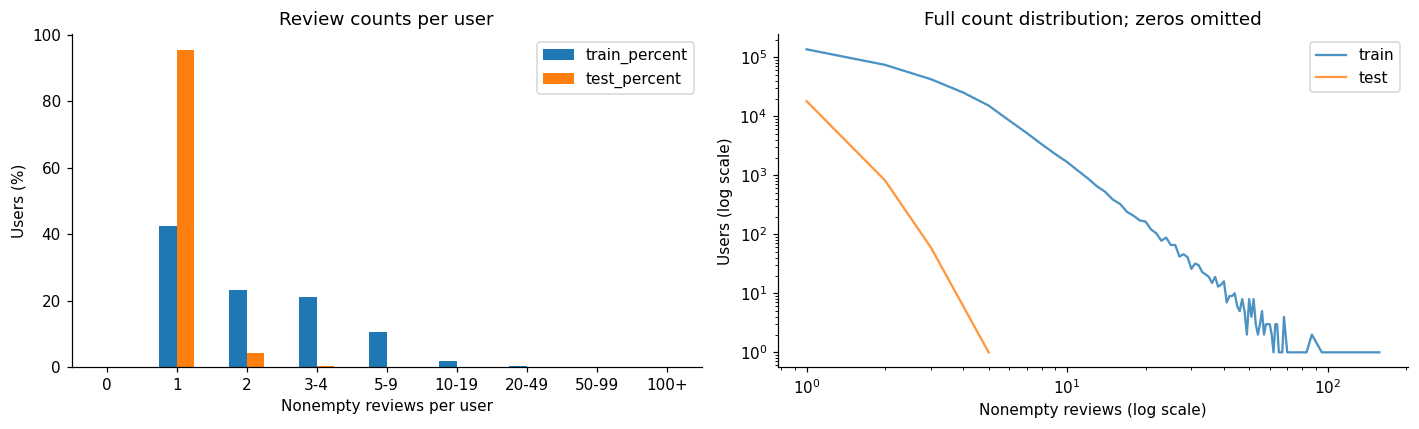

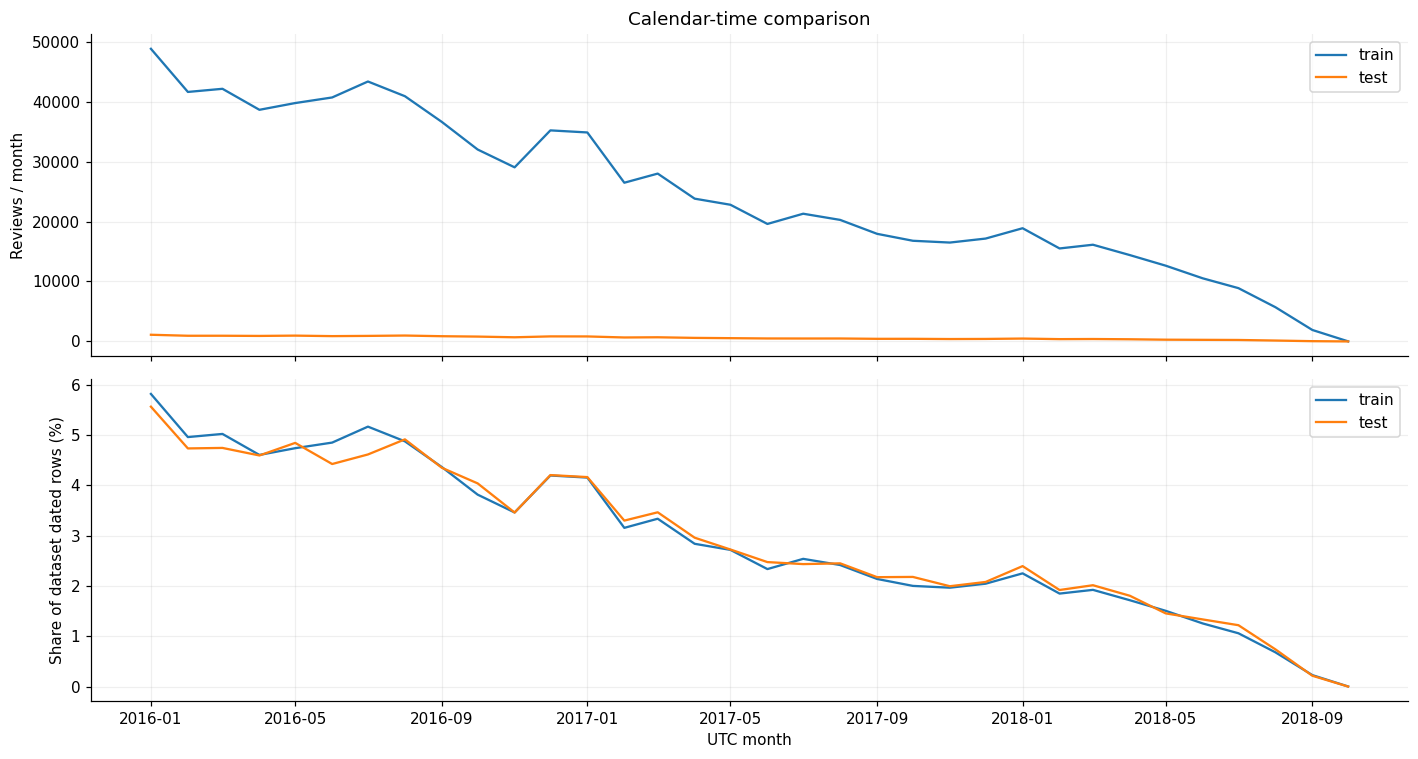

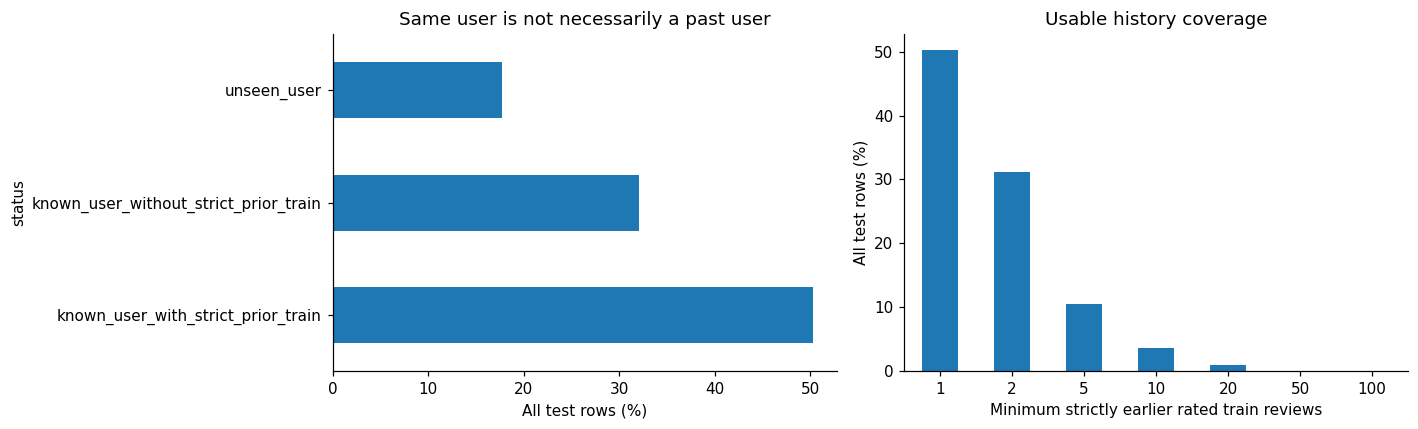


user_overlap


,value
train_unique_users,321135.000000
test_unique_users,19037.000000
shared_unique_users,15541.000000
train_only_users,305594.000000
test_only_users,3496.000000
shared_pct_of_train_users,4.839398
shared_pct_of_test_users,81.635762
test_rows_from_seen_users_pct_all_rows,82.240000
test_rows_from_unseen_users_pct_known_ids,17.760000



reviews_per_user_statistics


count      mean       std  min  25%  50%  75%  \
dataset measure                                                              
train   rows              321135.0  2.612434  2.852408  1.0  1.0  2.0  3.0   
        nonempty_reviews  321135.0  2.612434  2.852408  1.0  1.0  2.0  3.0   
test    rows               19037.0  1.050586  0.238442  1.0  1.0  1.0  1.0   
        nonempty_reviews   19037.0  1.050586  0.238442  1.0  1.0  1.0  1.0   

                          90%  95%   99%    max  single_review_users_pct  
dataset measure                                                           
train   rows              5.0  7.0  13.0  158.0                42.570259  
        nonempty_reviews  5.0  7.0  13.0  158.0                42.570259  
test    rows              1.0  1.0   2.0    5.0                95.335399  
        nonempty_reviews  1.0  1.0   2.0    5.0                95.335399


reviews_per_user_buckets


,train_count,train_percent,test_count,test_percent
nonempty_reviews,,,,
0,0,0.000000,0,0.000000
1,136708,42.570259,18149,95.335399
2,74572,23.221387,821,4.312654
3-4,67802,21.113239,66,0.346693
5-9,34582,10.768680,1,0.005253
10-19,6287,1.957744,0,0.000000
20-49,1106,0.344403,0,0.000000
50-99,71,0.022109,0,0.000000
100+,7,0.002180,0,0.000000


... (9 outputs left out)

,test_rows,pct_all_test_rows,pct_test_rows_with_valid_id_and_time,unique_test_users
min_prior_rated_reviews,,,,
1,10043,50.215,50.215,9471
2,6246,31.230,31.230,5840
5,2104,10.520,10.520,1892
10,717,3.585,3.585,617
20,188,0.940,0.940,156
50,18,0.090,0.090,15
100,4,0.020,0.020,4



same_time_excluded


,value
test_rows_with_same_time_train_records,5745.000
pct_of_all_test_rows,28.725
test_rows_with_earlier_unrated_records_only,0.000



METHOD NOTES
- Full original train and test files; no 50% sampling or model training.
- Users are identified by stripped, case-sensitive reviewerID; missing IDs are excluded from user sets.
- reviews_per_user counts nonempty reviewText; the row-count measure is reported separately.
- Dates prefer unixReviewTime in seconds (UTC), falling back to reviewTime (US month-first / ISO).
- Dates outside [1990-01-01, execution date + 1 day] are treated as invalid; discrepancies are reported.
- Day mode excludes every train record on the same UTC date. Timestamp mode excludes exact ties only.
- Prior history is from ORIGINAL TRAIN ONLY, for the same user with train time strictly less than test time.
- No test rating is read or used, even if the test file unexpectedly has an overall column.
- prior_rated_rows additionally requires a valid overall in {1,2,3,4,5}; empty training text does not invalidate an observed rating.
- Missing user/time cannot establish history; zero-filled audit counts for s

In [7]:
tables=make_analysis(train,test,train_quality,test_quality,OUTPUT_DIR,
                     TIME_GRANULARITY,EXPORT_PER_ROW)


## ۵. ذخیره و دانلود نتایج برای ارسال

سلول زیر فایل `amazon_train_test_audit_results.zip` می‌سازد و در Colab دانلود می‌کند. **همین ZIP را برای من بفرستید**؛ فایل summary.txt، جدول‌های CSV، نمودارها و تنظیمات اجرا داخل آن قرار دارند. اگر دانلود خودکار انجام نشد، آن را از پنل Files کولب دریافت کنید.

این بررسی به‌تنهایی روش واقعی ساخت test را اثبات نمی‌کند. حتی اگر بازه‌های زمانی هم‌پوشانی داشته باشند، بعضی کاربران ممکن است سابقهٔ مجاز زیادی و بعضی هیچ سابقه‌ای نداشته باشند. پس از دیدن خروجی، دربارهٔ تقسیم تصادفی/زمانی/گروهی و نحوهٔ محاسبهٔ سابقه تصمیم می‌گیریم. پوشش محاسبه‌شده برای **کل train اصلی** است؛ با استفاده از زیرمجموعهٔ آموزشی ممکن است کمتر شود.

مراجع پیاده‌سازی: [pandas merge_asof و شرط strictly earlier](https://pandas.pydata.org/docs/reference/api/pandas.merge_asof.html)، [gdown](https://github.com/wkentaro/gdown).


In [8]:
import shutil
zip_path=shutil.make_archive('/content/amazon_train_test_audit_results','zip',OUTPUT_DIR)
print('Results folder:',OUTPUT_DIR)
print('Share this file:',zip_path)
print('Summary:',OUTPUT_DIR/'summary.txt')
try:
    from google.colab import files
    files.download(zip_path)
except ImportError:
    print('Outside Colab: open or copy the ZIP path printed above.')


Results folder: /content/amazon_dataset_audit/20261105_161254_694153
Share this file: /content/amazon_train_test_audit_results.zip
Summary: /content/amazon_dataset_audit/20261105_161254_694153/summary.txt


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>